# Análisis Exploratorio de Datos (EDA): Precios de Referencia para Airbnb en Bogotá

**Proyecto:** Determinación de Precios de Referencia para Alojamientos Cortos en Bogotá <br>
**Autores:** Grupo 6 - Despliegue de Soluciones <br>
**Datasets:** Capturas de Inside Airbnb Bogotá (Junio 2026 y Septiembre 2026) <br>
**Versionamiento:** Datos rastreados mediante DVC (AWS S3) y código en GitHub <br>

En este cuaderno realizamos la carga, limpieza y análisis exploratorio de los conjuntos de datos de Inside Airbnb Bogotá para la información de **Junio 2026** y **Septiembre 2026**.

## 1. Importación de Librerias

In [1]:
import gzip
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 300

In [2]:
# Crear la carpeta para guardar las imágenes del informe
os.makedirs("reports/figures", exist_ok=True)

## 2\. Función de Carga

In [3]:
def cargar_y_limpiar(ruta_archivo):
    """
    Lee archivos .csv.gz y transforma la variable 'price' a formato float.
    """
    with gzip.open(ruta_archivo, "rt", encoding="utf-8") as f:
        df = pd.read_csv(f, low_memory=False)

    df["price"] = (
        df["price"]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
    )

    df["price"] = pd.to_numeric(df["price"], errors="coerce")

    return df

## 3\. Carga de datos y filtrado de valores atípicos

In [4]:
# Carga de datasets
df_junio = cargar_y_limpiar("listings0626.csv.gz")
df_sept = cargar_y_limpiar('listings0926.csv.gz')

In [20]:
print(df_junio.shape)
df_junio.head()

(19187, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,27841,https://www.airbnb.com/rooms/27841,20260621155658,2026-06-22,city scrape,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,NaN,https://a0.muscache.com/pictures/38377482/1df3...,113734,...,4.81,4.93,4.81,112727.0,NaN,3,3,0,0,0.24
1,65762,https://www.airbnb.com/rooms/65762,20260621155658,2026-06-22,city scrape,Apartaestudios La Candelaria,"In Bogota's historic center, near museums, res...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,321447,...,4.73,4.79,4.70,100613.0,NaN,24,22,2,0,0.19
2,138660,https://www.airbnb.com/rooms/138660,20260621155658,2026-06-22,city scrape,Excelent Studio ROSALES/ ZONA G,Ideal place if you want to settle down in Bogo...,NaN,https://a0.muscache.com/pictures/24594394/1ace...,676823,...,4.77,4.91,4.41,NaN,NaN,1,1,0,0,0.14
3,178850,https://www.airbnb.com/rooms/178850,20260621155658,2026-06-22,city scrape,"MODERN APARTMENT, 3 ROOMS, 4 PAX",NaN,NaN,https://a0.muscache.com/pictures/22dabfab-c264...,498646,...,5.00,4.67,5.00,NaN,NaN,2,2,0,0,0.03
4,289669,https://www.airbnb.com/rooms/289669,20260621155658,2026-06-22,city scrape,Room near to everything you need in Bogotá!,My house is located in one of the most iconic ...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,1503758,...,5.00,4.50,4.00,214760.0,NaN,3,0,3,0,0.01


In [21]:
print(df_sept.shape)
df_sept.head()

(19505, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,27841,https://www.airbnb.com/rooms/27841,20260914164224,2026-09-16,NaN,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,NaN,https://a0.muscache.com/pictures/38377482/1df3...,113734,...,4.81,4.93,4.81,112727.0,NaN,3,3,0,0,0.23
1,3043690,https://www.airbnb.com/rooms/3043690,20260914164224,2026-09-16,NaN,Room with a private,Located close to Parque Lourdes and within eas...,NaN,https://a0.muscache.com/pictures/46939629/35da...,15499337,...,4.63,4.63,4.50,NaN,NaN,2,0,2,0,0.05
2,3218908,https://www.airbnb.com/rooms/3218908,20260914164224,2026-09-16,NaN,"Nice vintage flat near to 93 park, well located","This flat is Inspired from the Vintage style, ...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,16300536,...,4.77,4.96,4.83,183725.0,NaN,1,1,0,0,1.09
3,3247862,https://www.airbnb.com/rooms/3247862,20260914164224,2026-09-16,NaN,Room Best Location Virrey Park,"This is a single room, a perfect starting poin...",NaN,https://a0.muscache.com/pictures/60803566/e7da...,3775838,...,4.50,4.50,4.50,142019.0,NaN,1,0,1,0,0.01
4,3263631,https://www.airbnb.com/rooms/3263631,20260914164224,2026-09-16,NaN,Private and comfortabe room for 2,"Room w/double bed, clean towels & sheets, clos...",NaN,https://a0.muscache.com/pictures/103053685/5a2...,16503059,...,5.00,4.94,4.94,NaN,NaN,1,0,1,0,1.75


In [5]:
# Filtro de atípicos (Percentil 99)
limite_alto = df_junio["price"].quantile(0.99)

df_junio_clean = df_junio[
    (df_junio["price"] > 0)
    & (df_junio["price"] <= limite_alto)
].copy()

df_sept_clean = df_sept[
    (df_sept["price"] > 0)
    & (df_sept["price"] <= limite_alto)
].copy()

# Transformación logarítmica de la variable objetivo
df_junio_clean["log_price"] = np.log(df_junio_clean["price"])

## 4\. Resumen Estadístico de los Datasets

In [6]:
resumen = pd.DataFrame(
    {
        "Métrica / Característica": [
            "Total registros (filas)",
            "Total variables (columnas)",
            "Precio mediano (COP)",
            "Precio promedio (COP)",
            "Promedio noches mínimas",
        ],
        "Junio 2026 (Entrenamiento)": [
            f"{len(df_junio):,}",
            str(df_junio.shape),
            f"${df_junio_clean['price'].median():,.0f}",
            f"${df_junio_clean['price'].mean():,.0f}",
            f"{df_junio_clean['minimum_nights'].mean():.1f}",
        ],
        "Septiembre 2026 (Evaluación)": [
            f"{len(df_sept):,}",
            str(df_sept.shape),
            f"${df_sept_clean['price'].median():,.0f}",
            f"${df_sept_clean['price'].mean():,.0f}",
            f"{df_sept_clean['minimum_nights'].mean():.1f}",
        ],
    }
)

print("--- TABLA DESCRIPTIVA DE DATASETS ---")
display(resumen)

--- TABLA DESCRIPTIVA DE DATASETS ---


,Métrica / Característica,Junio 2026 (Entrenamiento),Septiembre 2026 (Evaluación)
0,Total registros (filas),"19,187","19,505"
1,Total variables (columnas),"(19187, 90)","(19505, 90)"
2,Precio mediano (COP),"$160,000","$160,000"
3,Precio promedio (COP),"$195,110","$192,702"
4,Promedio noches mínimas,6.9,6.5


## 5\. Exploración de Datos

### Precio por Noche

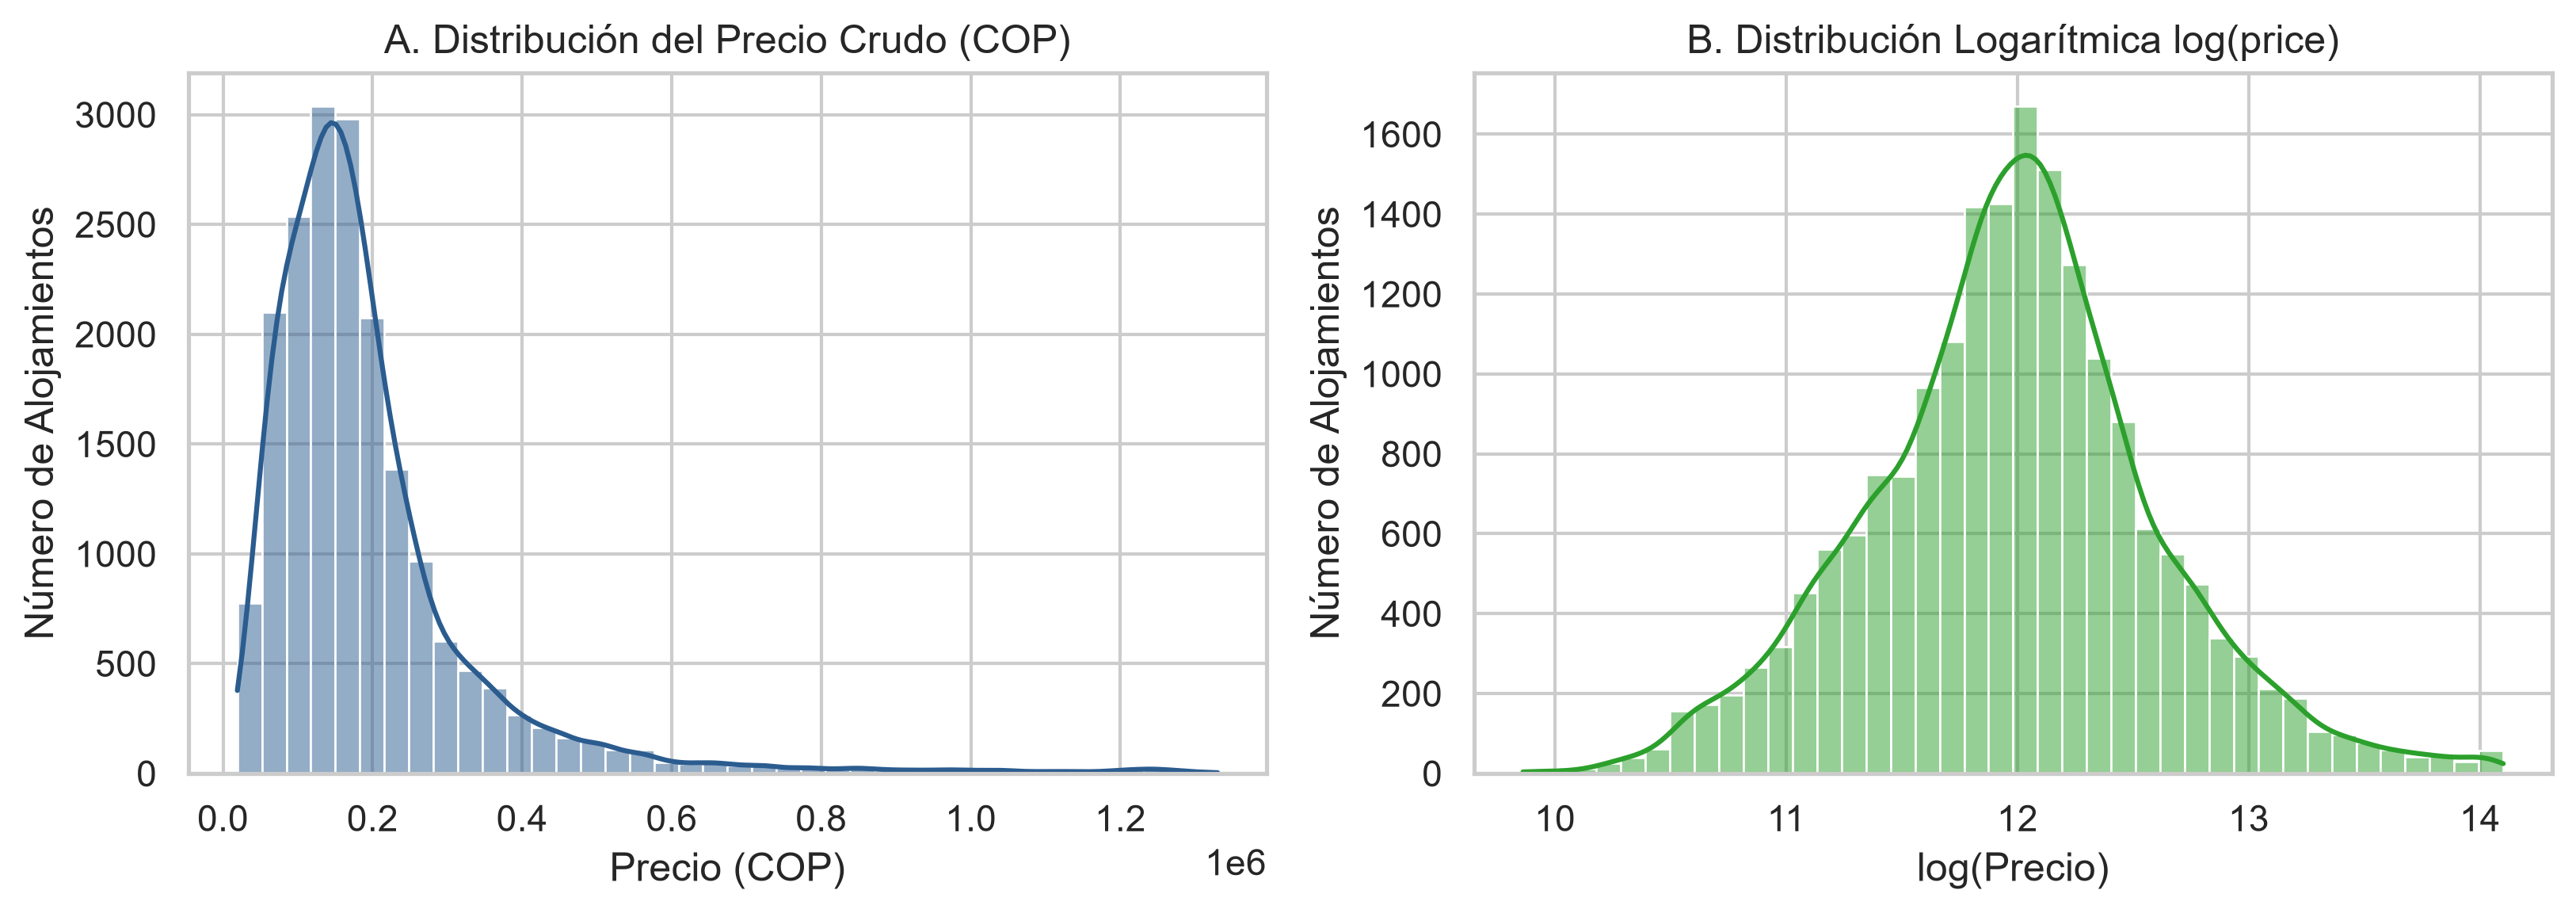

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(
    df_junio_clean["price"],
    bins=40,
    kde=True,
    ax=axes[0],
    color="#2b5c8f",
)

axes[0].set_title("A. Distribución del Precio Crudo (COP)")
axes[0].set_xlabel("Precio (COP)")
axes[0].set_ylabel("Número de Alojamientos")

sns.histplot(
    df_junio_clean["log_price"],
    bins=40,
    kde=True,
    ax=axes[1],
    color="#2ca02c",
)

axes[1].set_title("B. Distribución Logarítmica log(price)")
axes[1].set_xlabel("log(Precio)")
axes[1].set_ylabel("Número de Alojamientos")

plt.tight_layout()
plt.savefig("reports/figures/01_distribucion_y_log.png", dpi=300)
plt.show()

### Localidades con mayor oferta

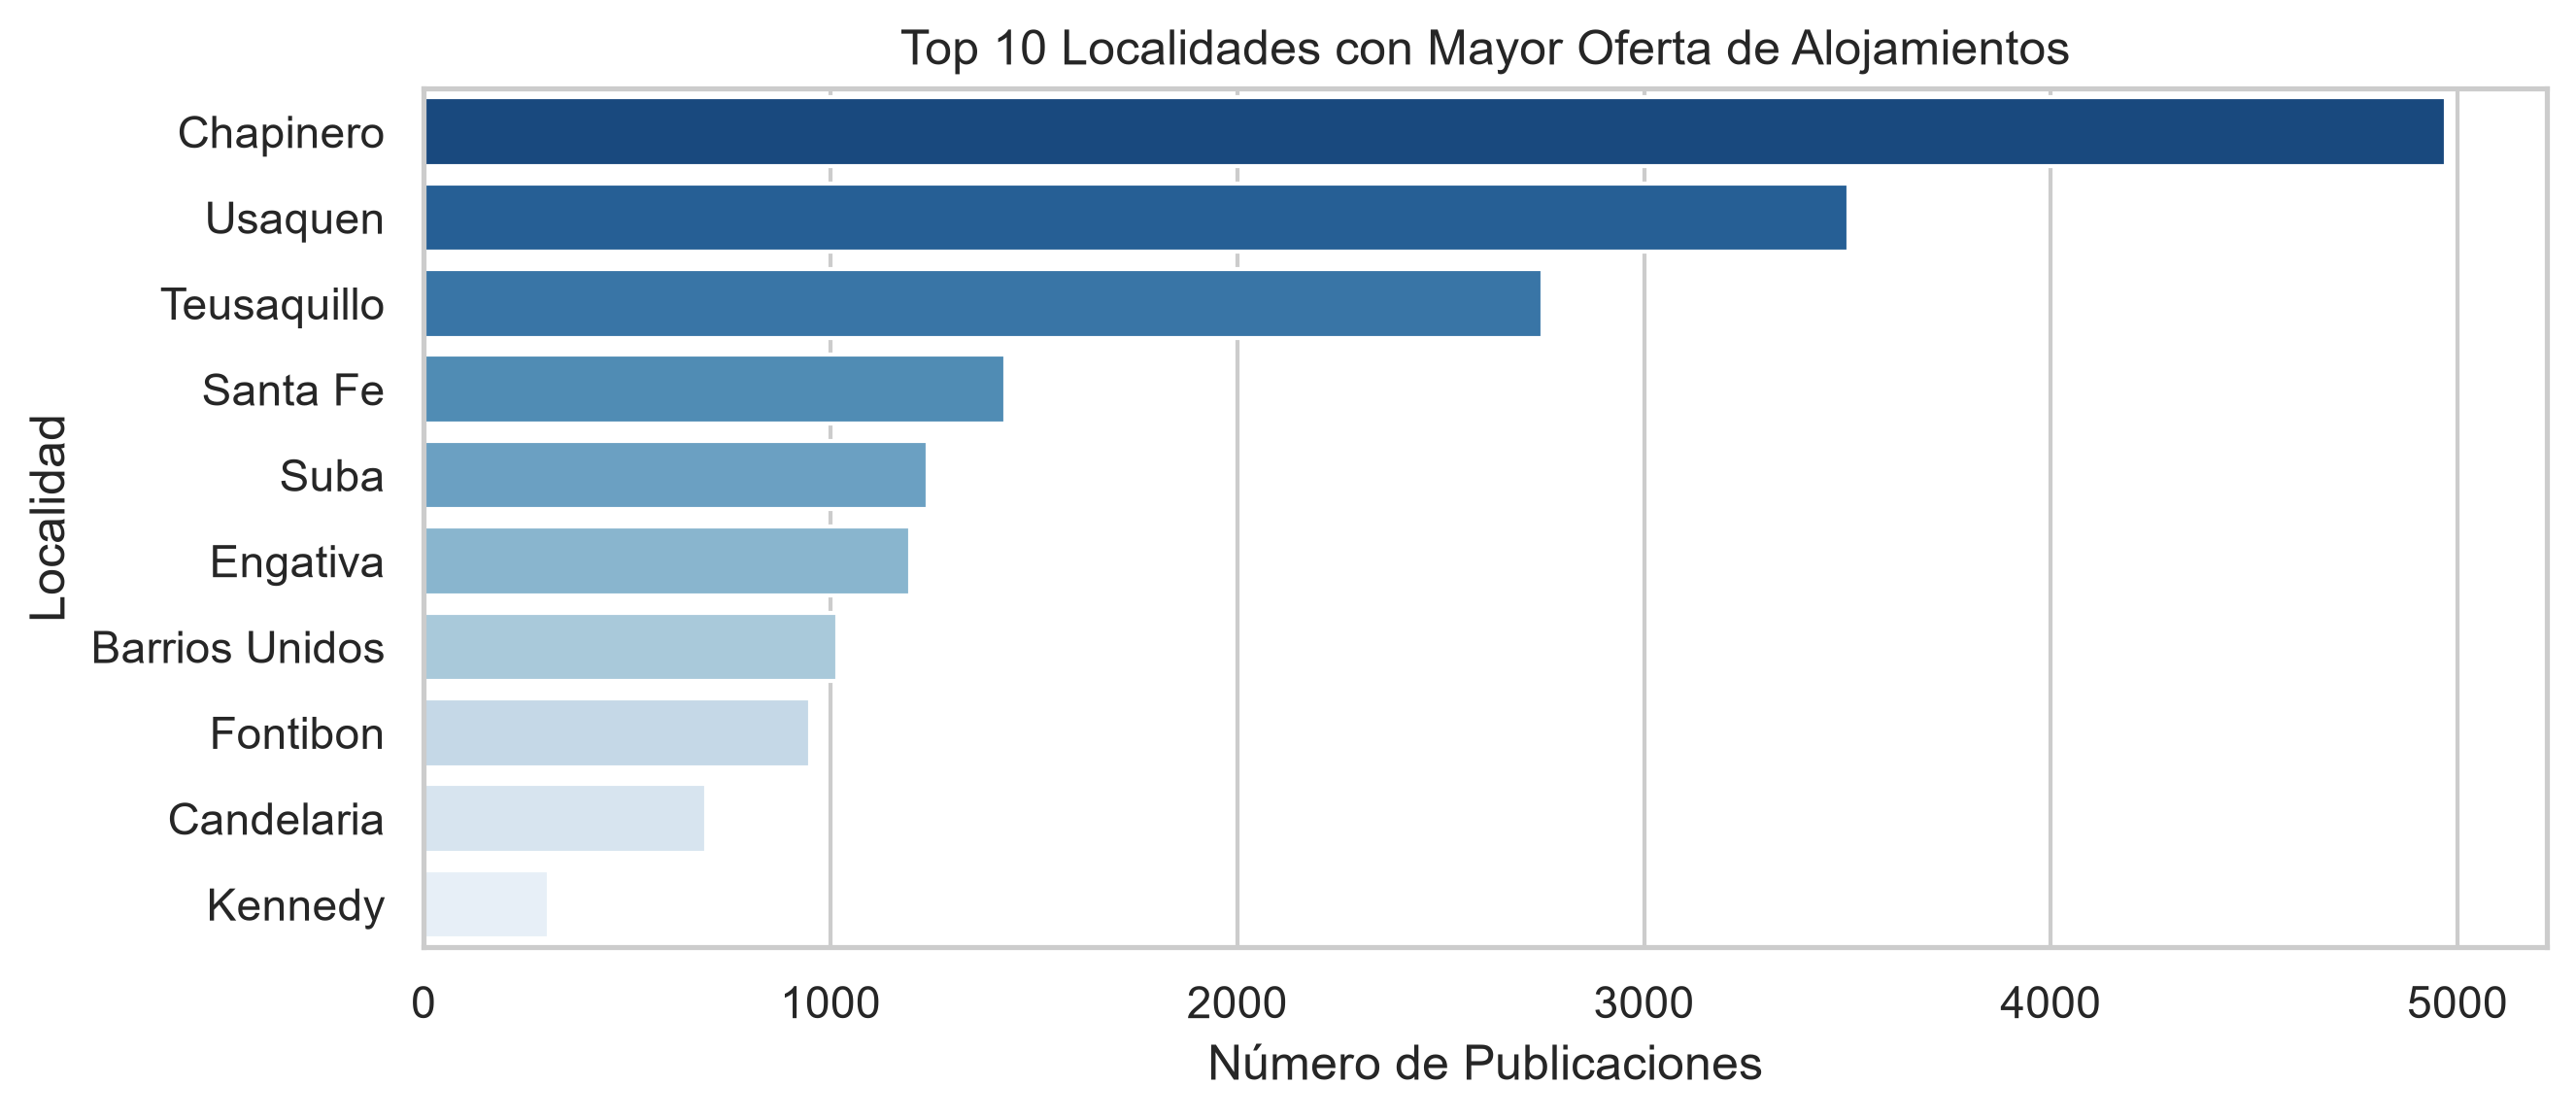

In [9]:
plt.figure(figsize=(9, 4))

top_localidades = (
    df_junio_clean["neighbourhood_cleansed"]
    .value_counts()
    .head(10)
)

sns.barplot(
    x=top_localidades.values,
    y=top_localidades.index,
    hue=top_localidades.index,
    palette="Blues_r",
    legend=False,
)

plt.title("Top 10 Localidades con Mayor Oferta de Alojamientos")
plt.xlabel("Número de Publicaciones")
plt.ylabel("Localidad")

plt.tight_layout()
plt.savefig("reports/figures/02_oferta_localidades.png", dpi=300)
plt.show()

### Comparación de precios por tipo de habitación

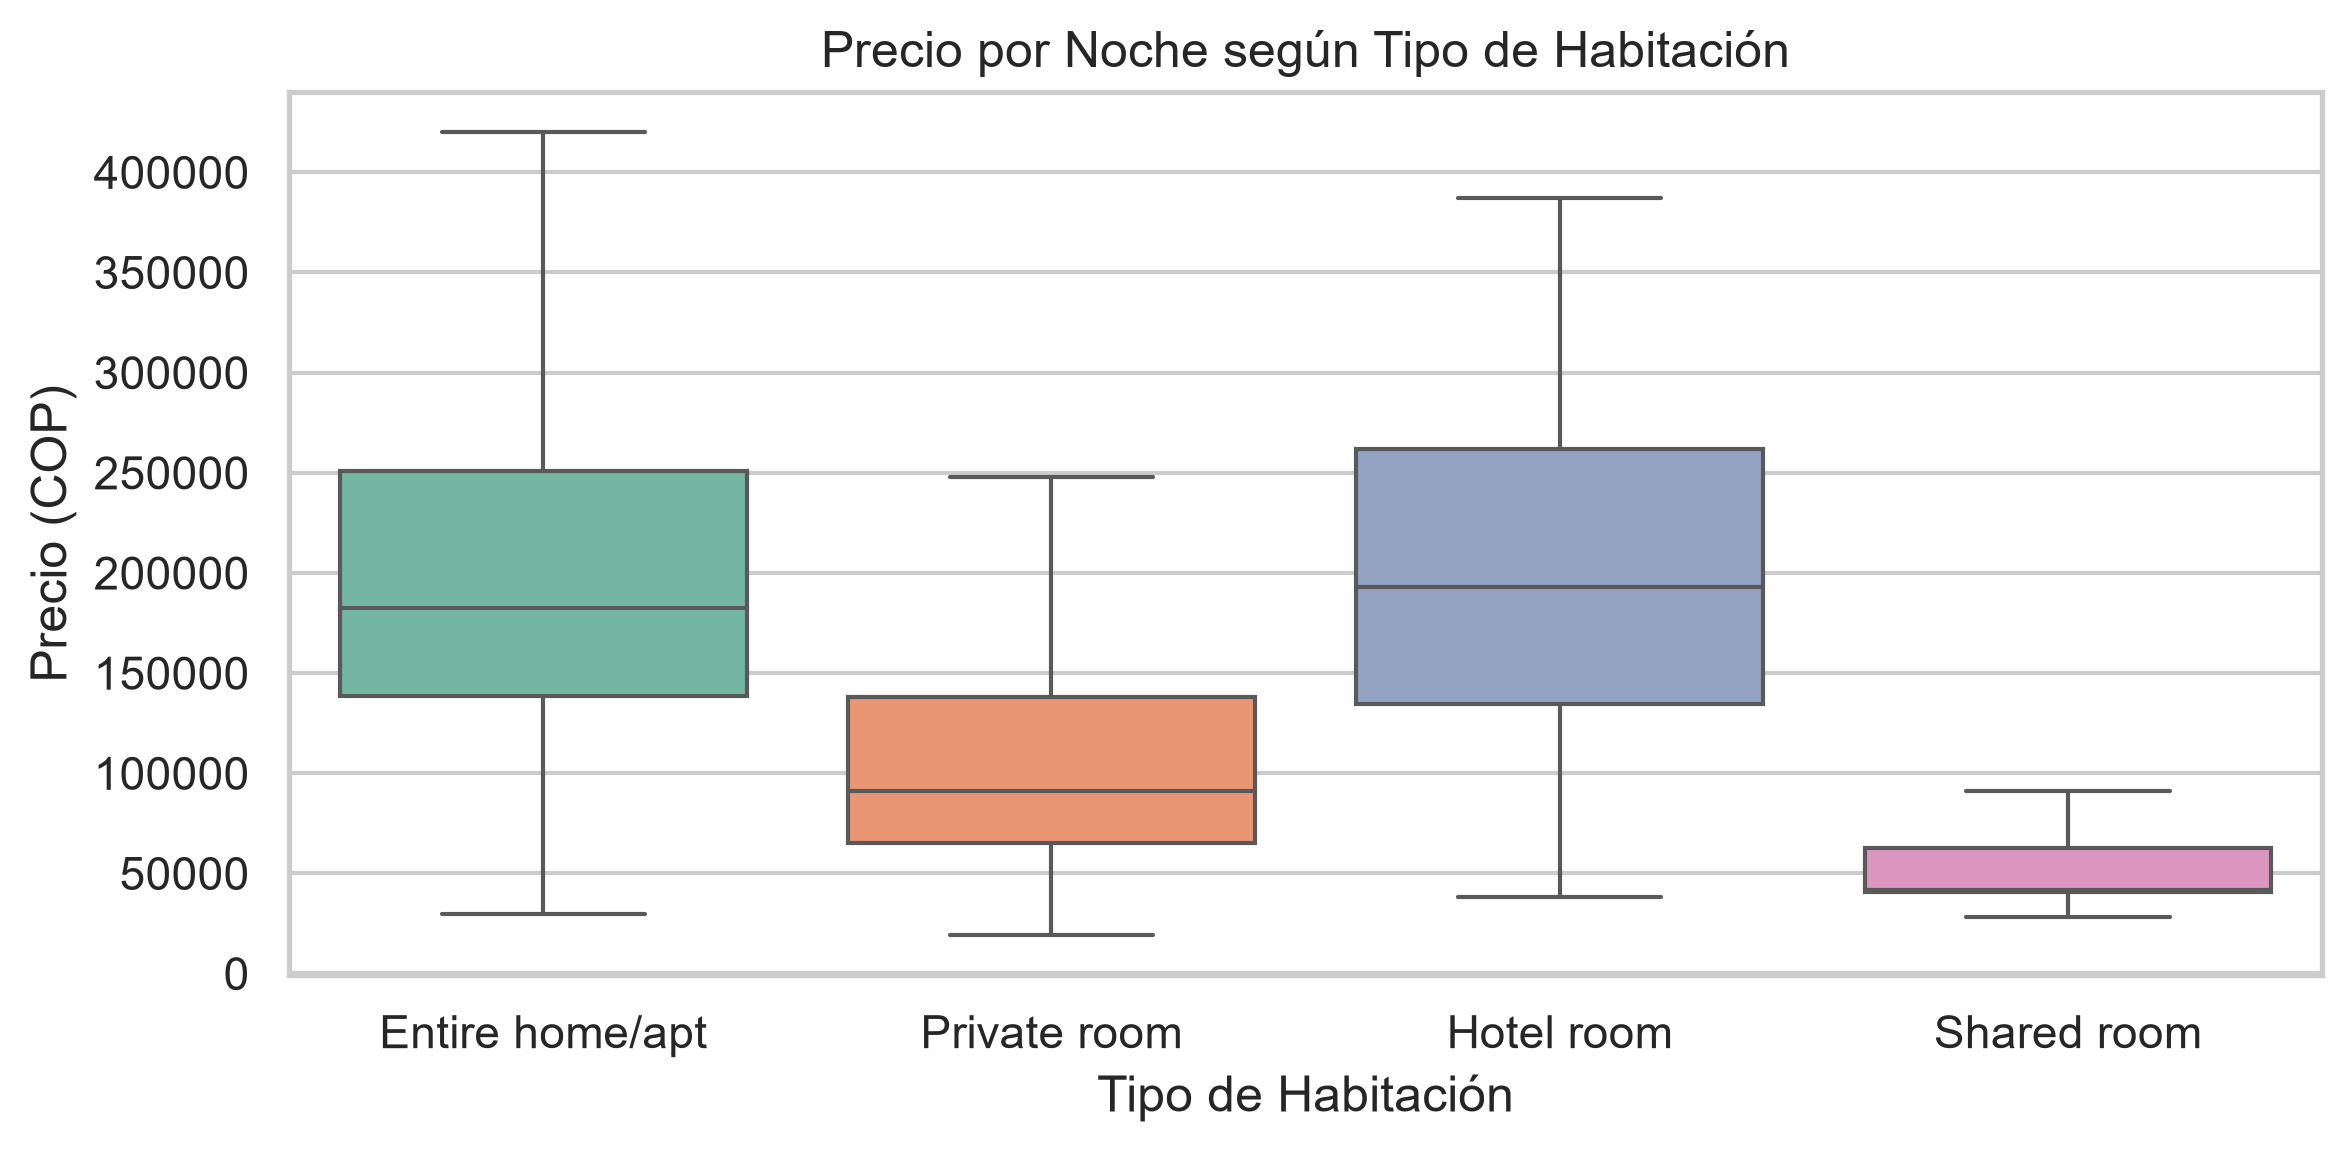

In [10]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df_junio_clean,
    x="room_type",
    y="price",
    hue="room_type",
    palette="Set2",
    showfliers=False,
    legend=False,
)

plt.title("Precio por Noche según Tipo de Habitación")
plt.xlabel("Tipo de Habitación")
plt.ylabel("Precio (COP)")

plt.tight_layout()
plt.savefig("reports/figures/03_precio_tipo_habitacion.png", dpi=300)
plt.show()

### Matriz de correlación de variables numéricas

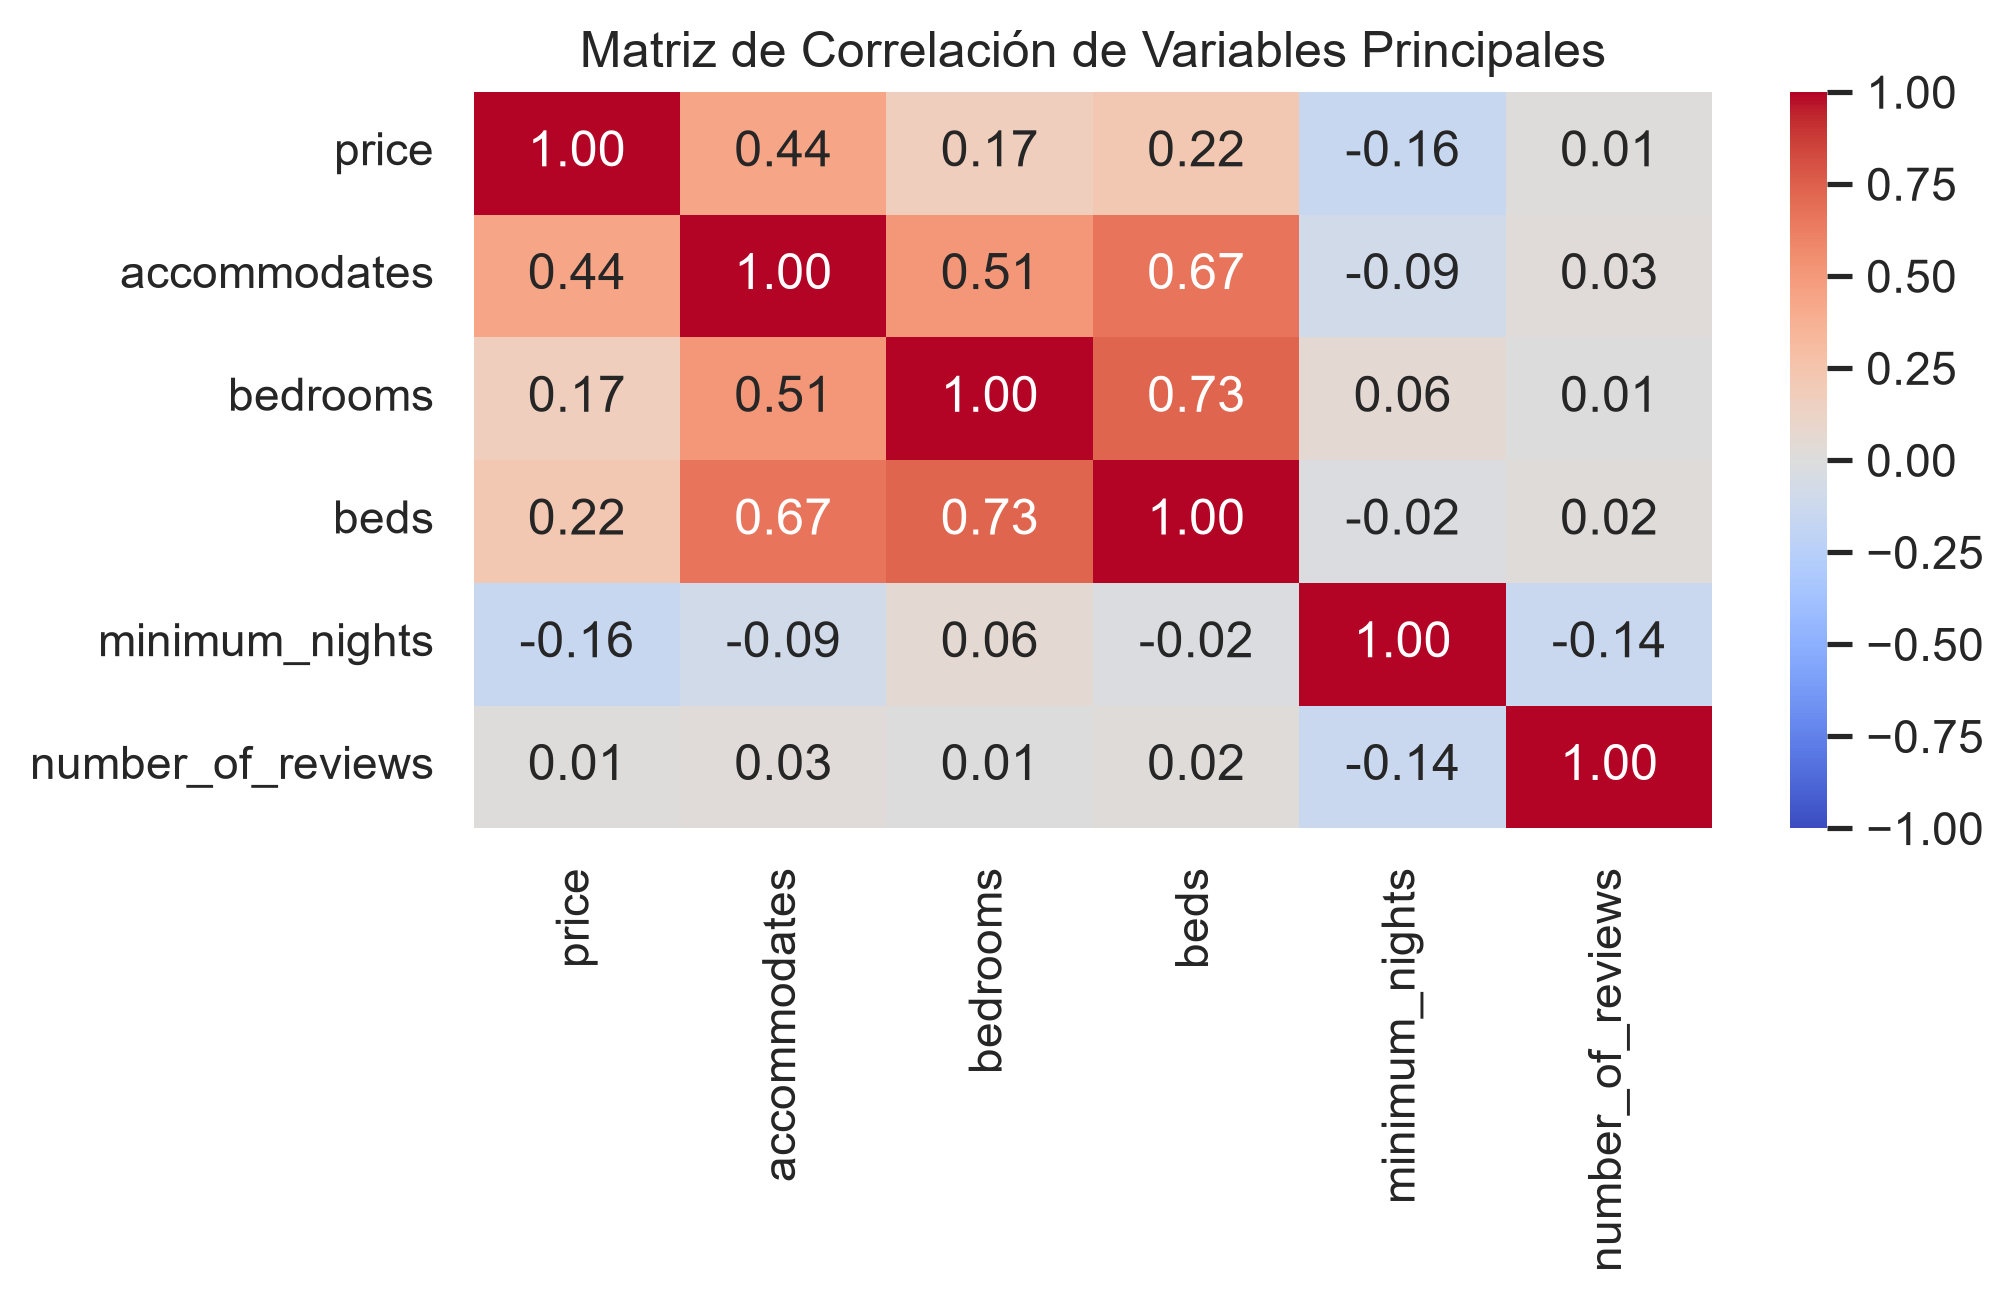

In [12]:
variables_num = [
    "price",
    "accommodates",
    "bedrooms",
    "beds",
    "minimum_nights",
    "number_of_reviews",
]

correlacion = df_junio_clean[variables_num].corr()

plt.figure(figsize=(7, 4.5))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
)

plt.title("Matriz de Correlación de Variables Principales")

plt.tight_layout()
plt.savefig("reports/figures/04_matriz_correlacion.png", dpi=300)
plt.show()